In [1]:
import networkx as nx
from BSutils import *
from scipy.stats import unitary_group
import matplotlib.pyplot as plt

[[0 1 0 1 1]
 [1 0 0 1 0]
 [0 0 0 0 1]
 [1 1 0 0 1]
 [1 0 1 1 0]]


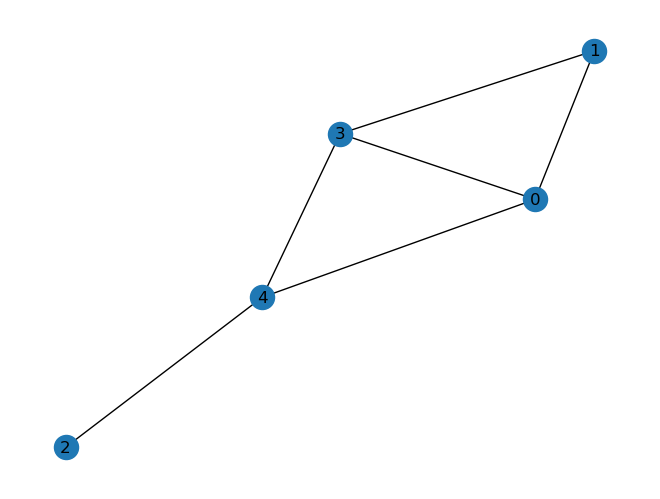

In [2]:
nodes = 5

p = 0.6
G = nx.erdos_renyi_graph(nodes,p=p)


pos = nx.spring_layout(G, seed=42)

adj = nx.adjacency_matrix(G).toarray()

print(adj)



nx.draw( G , with_labels = True,pos=pos) 
plt.show()
# Dstate

In [3]:
a,lsv = get_unitary_la(adj)

In [4]:
# nodes = 10
# density = np.random.uniform(0.1,1,size=1_00_000)
# lsvs = []
# proba_success_postselect = []
# for i,p in enumerate(density):
# 	print(i)
# 	while(True):
# 		G = nx.erdos_renyi_graph(nodes,p=p)
# 		adj = nx.adjacency_matrix(G).toarray()
# 		if(np.all(adj==0)):
# 			continue
# 		else:
# 			break
# 	# print(adj)
# 	a,lsv = get_unitary_la(adj)
# 	lsvs.append(lsv)
	




In [5]:
# plt.scatter(density,lsvs, marker='.',alpha=0.2)
# max(lsvs)

In [6]:
print(lsv)

2.6411864761932913


In [7]:
np.allclose(a@a.T.conj(),np.eye(2*nodes))

True

In [8]:
subgraph = list(np.random.choice([0,1],size=nodes))

In [9]:
k = sum(subgraph)
subgraph


[0, 0, 1, 1, 1]

In [10]:
# break

In [11]:
# subgraph+[0]*nodes
b = np.array(a,dtype=complex)
print(b.shape)
np.abs(expectation_value_permanent(b,subgraph+[0]*nodes))**2

(10, 10)


0.0

In [12]:
# s_o = [[(0,1),(1,1)]]*nodes+[[(0,1)]]*nodes
state_translator = [ [(i,1)] for i in subgraph]
s_in = state_translator +[[(0,1)]]*nodes
s_o=s_in

sampler = LimOh_sampler(s_in,s_o,b,1000000,verbose=2)
sampler.trust=True



# for _ in range(10):
	# print(np.abs((approx(s_in,s_o,a.T.conj(),size=10000)))**2)

In [13]:
list(nx.find_cliques(G))



[[0, 3, 1], [0, 3, 4], [2, 4]]

In [14]:
a = find_maxclique(G,method='exact',verbose=2)
a

search for  5
[('11111', 2.0)]
search for  4
[('11011', 4.0), ('11101', 1.0), ('10111', 1.0), ('01111', 1.0)]
search for  3
[('11010', 2.0), ('10011', 2.0), ('11001', 0.0), ('10101', 0.0), ('01011', 0.0), ('00111', 0.0)]


[[0, 1, 3]]

In [15]:
# finder = find_densest_subgraph(G,k,method='exact',verbose=0)

In [16]:
a = find_maxclique(G,method='approximate_sbs',Nsamples=100000,verbose=0)
a

[[0, 3, 4]]

In [17]:
break

SyntaxError: 'break' outside loop (668683560.py, line 1)

In [ ]:
G
method='approximate_sbs'
out_candidates=1
verbose=0
Nsamples=100_000

counter = 0
cliques = []
m = G.number_of_nodes()
candidates_k = []
# for k in range(m,2,-1):
k = m//2
if(verbose>=1):
	print("search for ", k)

finder = find_densest_subgraph(G,k,method=method,Nsamples=Nsamples,verbose=verbose-1)

In [ ]:
finder.run()

(0.6833948043251304-0.016967113424430996j)


In [ ]:
print(finder.results_estimators())
l = finder.results_estimators()[0]
print(l[0])
nodes = [i for i,e in enumerate(l[0]) if e=='1' ]
cliques.append(nodes)
nodes

[('10010', <BSutils.LimOh_sampler object at 0x3025c0390>), ('10001', <BSutils.LimOh_sampler object at 0x3025eb310>), ('00101', <BSutils.LimOh_sampler object at 0x3025eb390>), ('01010', <BSutils.LimOh_sampler object at 0x3025eb410>)]
10010


[0, 3]